# Algoritmos de Procura

Trabalho realizado por:
- Francisco Lopes nº111358
- Raul Azevedo nº111479

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time

## Exercício 1

### Alínea a - Gerar um padrão aleatório de bits 

A função `random_pattern` gera um padrão aleatório de **n** bits.

O resultado é devolvido como uma **string** de 0s e 1s.

In [2]:
def random_pattern(n, rng):
    bits = rng.integers(0, 2, size=n)
    return ''.join(map(str, bits))
    

### Alínea b - Força Bruta

A função `brute_force` implementa o algoritmo de procura por força bruta. Esta gera padrões aleatórios até encontrar uma correspondência exata com o padrão-alvo.

**Funcionamento:**
1. Guarda o instante inicial e coloca o contador de tentativas `attempts` a zero.
2. Em cada iteração verifica se o `deadline` foi atingido. Se sim, lança um `TimeoutError`.
3. Incrementa o contador `attempts` e gera um palpite com `random_pattern`. Se for igual ao alvo, o ciclo termina.
4. Devolve o número de tentativas e o tempo gasto

In [ ]:
def brute_force(target, rng, deadline):
    n = len(target)
    attempts = 0
    start = time.perf_counter()
    while True:
        if time.perf_counter() >= deadline:
            raise TimeoutError

        attempts += 1
        if random_pattern(n, rng) == target:
            break
        
    return attempts, time.perf_counter() - start

A função `run_experiment` implementa a força bruta para diferentes tamanhos do target e guarda os seus respetivos resultados.

**Funcionamento**
1. Para cada `n` da lista `SIZES`, define um `deadline` de 15 minutos (`TIME_LIMIT`) que se aplica ao conjunto dos 30 trials desse `n`.
2. Faz 30 trials, um por seed de `SEEDS`. Em cada um, cria um gerador com essa seed, gera o target e chama `brute_force`. O uso de seeds fixas torna a experiência reproduzível.
3. Guarda o número de tentativas e o tempo de cada trial em duas listas, que depois servem para os box-plots.
4. Se o `TimeoutError` for lançado, o `n` em causa é descartado e a experiência pára, visto que tamanhos maiores seriam ainda mais lentos.
5. Devolve o dicionário `results`, com chave `n` e valor `(attempts, times)`.

In [4]:
SEEDS = list(range(30))
TIME_LIMIT = 15 * 60 # 15 minutos em segundos
SIZES = [2, 4, 8, 12, 16, 20, 24, 28, 32]

def run_experiment(sizes):
    results = {}
    for n in sizes:
        attempts, times = [], []
        deadline = time.perf_counter() + TIME_LIMIT
        
        try:
            for seed in SEEDS:
                rng = np.random.default_rng(seed)
                target = random_pattern(n, rng)

                a, t = brute_force(target, rng, deadline)

                attempts.append(a)
                times.append(t)

        except TimeoutError:
            print(f"Limite de tempo excedido para n={n}.")
            break

        results[n] = (attempts, times)
        total_time = sum(times)
        print(f"n={n:2d} | média tentativas={np.mean(attempts):,.0f} | tempo total={total_time:.1f}s")

    return results

results = run_experiment(SIZES)

n= 2 | média tentativas=4 | tempo total=0.0s
n= 4 | média tentativas=19 | tempo total=0.0s
n= 8 | média tentativas=348 | tempo total=0.1s
n=12 | média tentativas=3,254 | tempo total=0.7s
n=16 | média tentativas=64,490 | tempo total=14.0s
n=20 | média tentativas=904,935 | tempo total=214.0s
Limite de tempo excedido para n=24.


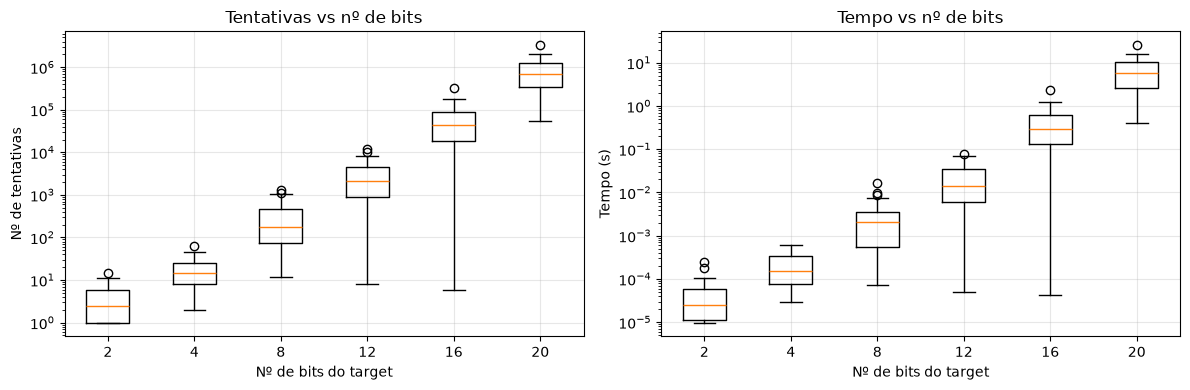

In [6]:
def plot_results(results):
    sizes = list(results)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    configs = [(0, "Nº de tentativas", "Tentativas vs nº de bits"),
               (1, "Tempo (s)", "Tempo vs nº de bits")]
    for ax, (idx, ylabel, title) in zip(axes, configs):
        ax.boxplot([results[n][idx] for n in sizes], positions=range(len(sizes)))
        ax.set_xticks(range(len(sizes)))
        ax.set_xticklabels(sizes)
        ax.set_yscale("log")
        ax.set_xlabel("Nº de bits do target")
        ax.set_ylabel(ylabel)
        ax.set_title(title)
        ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

plot_results(results)

**Resultados e Observações - Força bruta**

| n (bits) | Média de tentativas | Tempo total (30 trials) |
|---|---|---|
| 2 | 4 | ~0 s |
| 4 | 19 | ~0 s |
| 8 | 348 | 0.1 s |
| 12 | 3 254 | 0.7 s |
| 16 | 64 490 | 14.0 s |
| 20 | 904 935 | 214.0 s |
| 24 | — | limite de 15 min excedido |

**Tentativas:** O número de tentativas cresce de forma exponencial com o tamanho do target: de 4 tentativas em média com 2 bits passa para cerca de 905 mil com 20 bits. 

**Tempo:** O tempo acompanha o número de tentativas, e os dois gráficos têm uma forma muito semelhante. Passa de valores desprezáveis (n ≤ 4) para 14 s com 16 bits e 214 s com 20 bits, no conjunto dos 30 trials.

**Dispersão:** Os resultados variam bastante entre trials do mesmo tamanho. Para n = 12 e n = 16 há trials que acertam com muito poucas tentativas (bigodes inferiores longos), e em vários tamanhos existem *outliers* acima da caixa. A mediana fica abaixo da média (por exemplo, em n = 16 a mediana ronda as 4×10⁴ tentativas e a média é de 64 490), o que mostra que alguns trials mais lentos puxam a média para cima.


**Escolha do tamanho:** O maior padrão que completou os 30 trials em tempo razoável foi **n = 20** (214 s), e será o tamanho usado nos exercícios seguintes.